# Plotter manual tests

## Test as a function first

In [13]:
from circle import Circle
from rectangle import Rectangle

from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle as MplRectangle
from matplotlib.patches import Circle as MplCircle

def plot2d(*shapes: Circle | Rectangle) -> tuple[plt.Figure, plt.Axes]:
    for shape in shapes:
        if not isinstance(shape, Circle | Rectangle):
            raise TypeError(f"Shape must be a Circle or Rectangle object, not {type(shape).__name__}")

    fig, axes = plt.subplots()

    for shape in shapes:
        if isinstance(shape, Rectangle):
            axes.add_patch(
                MplRectangle(
                    xy=(shape.x - (shape.width / 2), shape.y - (shape.height / 2)), # x, y in Shape objects represent the center. Subtract half of width and height to match bottom-left
                    width=shape.width,
                    height=shape.height,
                    facecolor="none",
                    edgecolor="black"
                    )
                )

        if isinstance(shape, Circle):
            axes.add_patch(
                MplCircle(
                    xy=(shape.x, shape.y),
                    radius=shape.radius,
                    facecolor="none",
                    edgecolor="blue"
                    )
                )

    # Equalize aspect ratio to prevent distorted shapes
    axes.autoscale_view(True)
    axes.axhline(0)
    axes.axvline(0)
    axes.set(aspect="equal")

    plt.show()    
    

### Call function with test values

In [14]:
import random as rnd

shapes = []

for i in range(6):
    shapes.append(Rectangle(rnd.randint(1, 4), rnd.randint(1, 4), rnd.randint(-15, 15), rnd.randint(-15, 15)))
    shapes.append(Circle(rnd.randint(2, 4), rnd.randint(-15, 15), rnd.randint(-15, 15)))

#plot2d(*shapes)

## Use the new class

C:\Users\Dr. Kiosk\AppData\Local\Temp\ipykernel_19584\1853698931.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


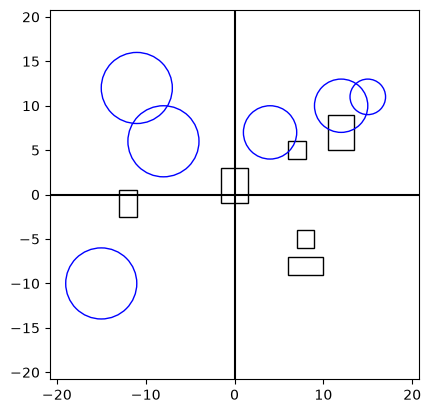

In [15]:
from shape2dplotter import Shape2DPlotter

fig, axes = Shape2DPlotter.plot2d(*shapes)
fig.show()

## Test abs max idea for getting max extent for a centered (0, 0) coordinate system

In [16]:
tup_1, tup_2 = (-20, 15), (-35, 24)

abs(max(max(*tup_1, key=abs), max(*tup_2, key=abs))) # 20 - Fail

abs(max((*tup_1, *tup_2), key=abs)) # 35 - Success but bad readability

35

### Cleaner more readable version

In [17]:
x_limits, y_limits = (-20, 15), (-35, 24)

furthest_coordinate = max((*x_limits, *y_limits), key=abs)
print(f"{furthest_coordinate = }")

max_extent = abs(furthest_coordinate)
print(f"{max_extent = }")

furthest_coordinate = -35
max_extent = 35


## For-loop with unpacking test

In [18]:
test_tuple_1, test_tuple_2 = (-20, 15), (-35, 24)

for value in *test_tuple_1, *test_tuple_2:
    print(f"{value = }")

value = -20
value = 15
value = -35
value = 24
